# 02 — EDA of activity over time (Person 3: GRU/LSTM) · owner: chad
**IT2226 Progress Review 1 · Win-Back Decision Agent · Part A, sequence model**

My model reads each customer's history **week by week** instead of as totals.
This notebook asks the questions that decide how to build it:

1. What does the weekly table look like — how empty (sparse) is it?
2. Is there **seasonality** across the business (weekly patterns, peaks)?
3. Do future buyers' sessions **rise in the weeks before** the cutoff?
4. Does the **shape** of the history ("slowing down", "picking up") matter beyond totals?
   — this is the whole reason for a sequence model
5. Check the brief's claim: "**one in three** customers inactive for 90 days"

Input: `data/processed/weekly_sequences.npz`, built by `python src/weekly_sequences.py`
(104 weeks × 4 numbers per customer: orders, spend, sessions, cart adds — all up to 30 Sep 2024).

**Only the TRAIN split is used for anything involving the target**, so the validation and test
customers stay untouched until the model is evaluated (team rule). The split comes from
`shopsphere.split.assign_split`, the one split the whole team uses.

In [1]:
import sys
from pathlib import Path

# Find the project root (the folder that contains src/), like the team's notebooks do.
ROOT = Path.cwd()
while not (ROOT / "src" / "shopsphere").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Shared team settings: paths, cutoff date and the one split. Never redefined here.
from shopsphere.config import CUTOFF_DATE, DATA_PROCESSED, DATA_RAW, FIGURES_DIR, ID_COL, TARGET_COL
from shopsphere.split import assign_split

FIG = FIGURES_DIR; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
BLUE, ORANGE, GREY = "#2a6f97", "#e07a1f", "#9aa5b1"
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150); plt.show()

d = np.load(DATA_PROCESSED / "weekly_sequences.npz")
seq, ids, CH = d["seq"], d["customer_id"], list(d["channels"])
N_WEEKS = seq.shape[1]
CUTOFF = pd.Timestamp(CUTOFF_DATE)
# start date of each time step (position N_WEEKS-1 = the week ending on the cutoff)
week_start = [CUTOFF - pd.Timedelta(days=7 * (N_WEEKS - 1 - i) + 6) for i in range(N_WEEKS)]
print("weekly table:", seq.shape, "channels:", CH)
print("first week starts", week_start[0].date(), "| last week", week_start[-1].date(), "to", CUTOFF.date())

# Labels: TRAIN split only (validation and test are kept for the model evaluation)
labels = assign_split(pd.read_csv(DATA_RAW / "train.csv"))
labels = labels[labels["split"] == "train"]
pos = pd.Series(np.arange(len(ids)), index=ids)
L = seq[pos[labels[ID_COL]].values]                 # train customers' sequences
y = labels[TARGET_COL].values
print(f"{len(y):,} TRAIN customers, buy rate {y.mean():.1%}")

weekly table: (80000, 104, 4) channels: [np.str_('orders'), np.str_('spend'), np.str_('sessions'), np.str_('cart_adds')]
first week starts 2022-10-04 | last week 2024-09-24 to 2024-09-30
44,800 TRAIN customers, buy rate 14.6%


## 1. How sparse is the weekly table?

Customer-weeks with any activity (all 104 weeks): 11.6%


Customer-weeks with any activity (last 52 weeks):  14.6%
Customers with ZERO active weeks in the last year: 23.4%
Median active weeks in the last year: 5 of 52


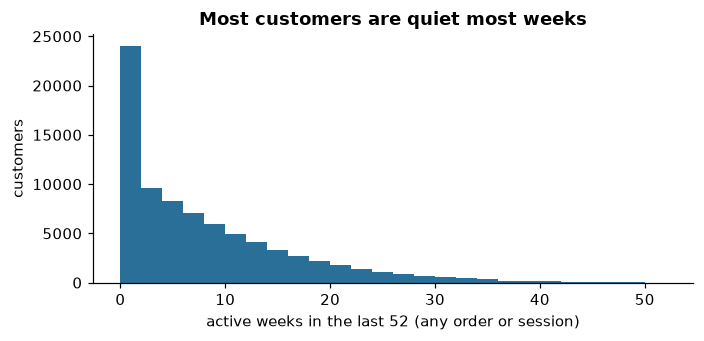

In [2]:
active = seq.sum(axis=2) > 0                        # True if the customer did anything that week
last52 = active[:, -52:]
print(f"Customer-weeks with any activity (all 104 weeks): {active.mean():.1%}")
print(f"Customer-weeks with any activity (last 52 weeks):  {last52.mean():.1%}")
n_active = last52.sum(axis=1)
print(f"Customers with ZERO active weeks in the last year: {(n_active == 0).mean():.1%}")
print(f"Median active weeks in the last year: {np.median(n_active):.0f} of 52")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(n_active, bins=np.arange(0, 54, 2), color=BLUE)
ax.set_xlabel("active weeks in the last 52 (any order or session)"); ax.set_ylabel("customers")
ax.set_title("Most customers are quiet most weeks")
save(fig, "chad_20_active_weeks_hist")

**Decision:** the table is mostly zeros with occasional spikes, and spend is heavily skewed,
so every channel gets `log(1+x)` and is then standardised (mean/std learned on **train only**).

## 2. Seasonality — the whole business, week by week

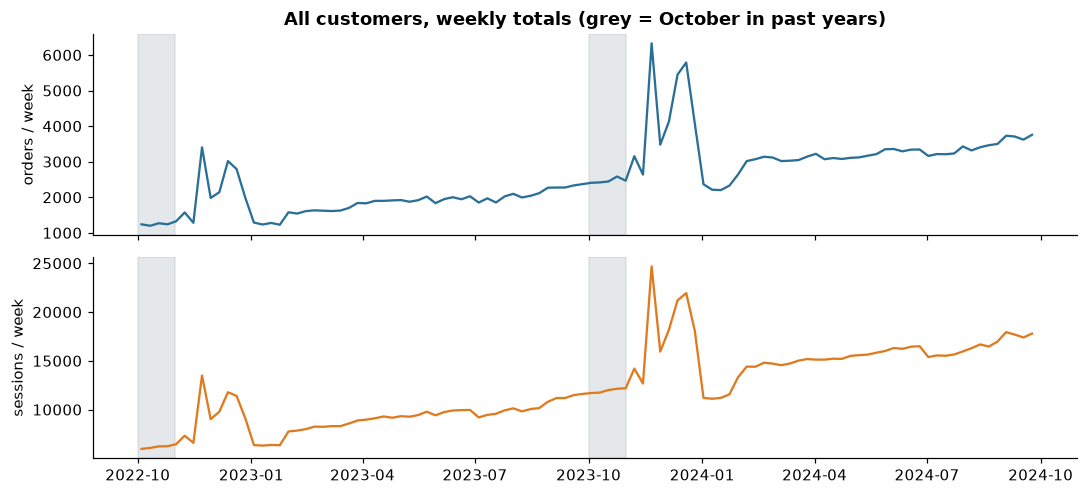

In [3]:
weekly_tot = pd.DataFrame(seq.sum(axis=0), columns=CH, index=pd.to_datetime(week_start))
fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
axes[0].plot(weekly_tot.index, weekly_tot["orders"], color=BLUE); axes[0].set_ylabel("orders / week")
axes[1].plot(weekly_tot.index, weekly_tot["sessions"], color=ORANGE); axes[1].set_ylabel("sessions / week")
for ax in axes:
    for yr in [2022, 2023]:                         # shade the October we are predicting, in past years
        ax.axvspan(pd.Timestamp(f"{yr}-10-01"), pd.Timestamp(f"{yr}-10-31"), color=GREY, alpha=0.25)
axes[0].set_title("All customers, weekly totals (grey = October in past years)")
save(fig, "chad_21_weekly_seasonality")

**Reading the chart:** two things move the whole business — a steady **growth trend** (orders
per week roughly tripled in two years) and a big **Nov–Dec holiday spike**, followed by a January drop.
October itself is a normal month just *before* the spike. Because every customer shares the same
calendar, this is mostly a "background" signal; what differs between customers is their own pattern.

## 3. Do future buyers become more active in the weeks before the cutoff?

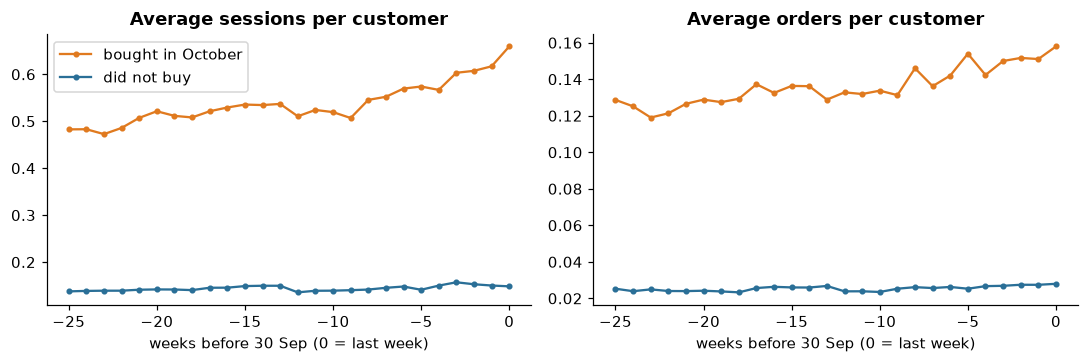

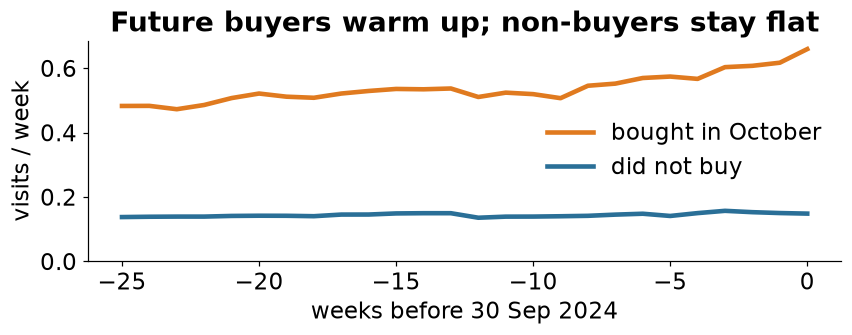

Buyers vs non-buyers, sessions per week: 3.5x half a year earlier -> 4.1x in the last 4 weeks


In [4]:
last = 26
buyers, nonbuyers = L[y == 1, -last:], L[y == 0, -last:]
x = np.arange(-last + 1, 1)                        # 0 = the last week before the cutoff
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, ch, title in [(axes[0], CH.index("sessions"), "sessions per customer"),
                      (axes[1], CH.index("orders"), "orders per customer")]:
    ax.plot(x, buyers[:, :, ch].mean(0), marker="o", ms=3, color=ORANGE, label="bought in October")
    ax.plot(x, nonbuyers[:, :, ch].mean(0), marker="o", ms=3, color=BLUE, label="did not buy")
    ax.set_xlabel("weeks before 30 Sep (0 = last week)"); ax.set_title(f"Average {title}")
axes[0].legend()
save(fig, "chad_22_buyers_vs_nonbuyers_weekly")

# a simpler, larger-font version of the sessions panel for the presentation slide
with plt.rc_context({"font.size": 15}):
    fig, ax = plt.subplots(figsize=(8, 3.3))
    ax.plot(x, buyers[:, :, CH.index("sessions")].mean(0), lw=3, color=ORANGE, label="bought in October")
    ax.plot(x, nonbuyers[:, :, CH.index("sessions")].mean(0), lw=3, color=BLUE, label="did not buy")
    ax.set_ylim(0, None); ax.set_ylabel("visits / week")
    ax.set_xlabel("weeks before 30 Sep 2024"); ax.legend(frameon=False, loc="center right")
    ax.set_title("Future buyers warm up; non-buyers stay flat")
    save(fig, "chad_24_buyers_sessions_slide")

ratio_now =buyers[:, -4:, CH.index("sessions")].mean() / nonbuyers[:, -4:, CH.index("sessions")].mean()
ratio_then = buyers[:, :4, CH.index("sessions")].mean() / nonbuyers[:, :4, CH.index("sessions")].mean()
print(f"Buyers vs non-buyers, sessions per week: {ratio_then:.1f}x half a year earlier -> {ratio_now:.1f}x in the last 4 weeks")

## 4. Does the *shape* of the history matter? ("slowing down" vs "picking up")
We compare each customer's last 4 weeks with the 12 weeks before them (weekly average of
orders + sessions) and put them in 5 groups.

In [5]:
act = L[:, :, CH.index("sessions")] + L[:, :, CH.index("orders")]
recent = act[:, -4:].mean(1)                       # weeks 1-4 before the cutoff
before = act[:, -16:-4].mean(1)                    # weeks 5-16 before the cutoff
trend = np.select(
    [(recent == 0) & (before == 0), (recent == 0) & (before > 0),
     recent < 0.5 * before, recent > 1.5 * before],
    ["inactive both", "stopped", "slowing down", "picking up"], default="steady")
tr = pd.DataFrame({"trend": trend, "bought": y, "recent": recent})
order = ["inactive both", "stopped", "slowing down", "steady", "picking up"]
summary = tr.groupby("trend").agg(customers=("bought", "size"), buy_rate=("bought", "mean")).loc[order]
summary["buy_rate"] = (summary["buy_rate"] * 100).round(1)
summary

,customers,buy_rate
trend,,
inactive both,16727,0.8
stopped,10238,11.3
slowing down,1299,43.9
steady,7881,32.7
picking up,8655,24.1


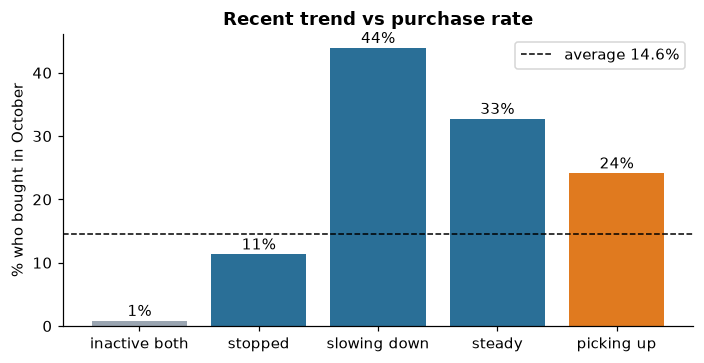

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(summary.index, summary["buy_rate"], color=[GREY, BLUE, BLUE, BLUE, ORANGE])
ax.axhline(y.mean() * 100, color="k", ls="--", lw=1, label=f"average {y.mean():.1%}")
for i, v in enumerate(summary["buy_rate"]): ax.text(i, v + 0.8, f"{v:.0f}%", ha="center")
ax.set_ylabel("% who bought in October"); ax.set_title("Recent trend vs purchase rate"); ax.legend()
save(fig, "chad_23_trend_vs_target")

**Same recent activity, different history?** The fair test of "shape matters" is to hold the
recent level fixed. Below: customers with the *same* activity in the last 4 weeks, split by
whether they were more or less active before.

In [7]:
tr["recent_band"] = pd.cut(recent, [-0.01, 0, 0.5, 1.5, 100], labels=["0", "0-0.5", "0.5-1.5", "1.5+"])
tr["history"] = np.where(before > recent, "was MORE active before", "was less / equally active before")
pivot = (tr.groupby(["recent_band", "history"], observed=True)["bought"].mean() * 100).round(1).unstack()
pivot

history,was MORE active before,was less / equally active before
recent_band,,
0,11.3,0.8
0-0.5,32.3,14.3
0.5-1.5,64.2,35.5
1.5+,92.5,68.1


## 5. Checking the brief: "one in three customers inactive for 90 days"

In [8]:
no_session_13w = L[:, -13:, CH.index("sessions")].sum(1) == 0
no_order_13w = L[:, -13:, CH.index("orders")].sum(1) == 0
print(f"No session in the last 13 weeks (≈90 days): {no_session_13w.mean():.1%}")
print(f"No order   in the last 13 weeks:            {no_order_13w.mean():.1%}")
print(f"Neither (fully inactive):                   {(no_session_13w & no_order_13w).mean():.1%}")
print(f"Buy rate of fully inactive customers: {y[no_session_13w & no_order_13w].mean():.1%}  vs active: {y[~(no_session_13w & no_order_13w)].mean():.1%}")

No session in the last 13 weeks (≈90 days): 40.2%
No order   in the last 13 weeks:            71.6%
Neither (fully inactive):                   40.2%
Buy rate of fully inactive customers: 1.2%  vs active: 23.6%


## 6. Summary and decisions for my GRU/LSTM model
(numbers from the run saved in this notebook, 44,800 TRAIN customers)

**What I found**
* **Sparse:** only 14.6% of customer-weeks in the last year have any activity; the median customer
  is active in 5 of 52 weeks, and 23% had no activity at all in the last year.
* **Seasonality:** the business grows steadily and spikes in Nov–Dec; October is a normal month.
* **Buyers warm up:** future buyers' sessions per week rise from 0.48 to 0.66 over the last 26 weeks
  (+37%), while non-buyers stay flat at about 0.14–0.15.
* **History matters, not just the recent level:** among customers with the *same* activity in the last
  4 weeks, those who were *more active before* buy far more often (64% vs 36%, and 93% vs 68%).
  Customers who **stopped** completely still buy 11% of the time vs 0.8% for those inactive throughout.
  Totals over one window cannot see this; a sequence model can.
* **Brief's claim:** 40.2% had no session in the last ~90 days — **worse than "one in three"**. They buy
  at only 1.2% vs 23.6% for active customers.

**Decisions**

| Finding | Decision |
|---|---|
| Mostly empty weeks with skewed spikes (spend especially) | `log(1+x)` then standardise each channel, statistics from **train only** |
| Buyers' activity rises in the last weeks | Put the newest week **last**, so the GRU's final state is driven by recent weeks |
| Earlier history changes the buy rate at the same recent level | A sequence model has real signal to learn — the reason this variant exists |
| Growth trend + yearly seasonality | Compare **26 vs 52 weeks** of history as a tuning choice |
| Static facts (tier, loyalty score...) are not in the weekly table | Also try a **hybrid**: GRU over the weeks + the team's `train_features.csv` |